# Electric Nation: descriptive analysis

Electric Nation (2017–18) supplies the **real EV charging load** that is added to Low Carbon
London households to build the synthetic EV dataset. About 560 home chargers were logged by two
providers in different formats. Each charger sat in one of five groups at any time: unmanaged
(not yet in a group), T1 control, T1 demand management, T2 priority-charging app and T3
time-of-use tariff. **Unmanaged appears only in the trial timeline (Figure EN1).** It is mostly
onboarding before a charger joins a group and is not used by the EV linkage (`05`), so every
other table and figure compares the four linkage regimes, with **T1 control** (drivers in the
trial, charging without management) as the unmanaged reference.

This notebook produces three tables and seven figures:
- a dataset summary;
- how much single-regime data each regime can supply, which sets the EV linkage design;
- charging behaviour statistics;
- the trial timeline, the vehicle fleet, charging frequency, charging energy by month, start
  times, mean demand per charger, and example carpet plots.

It also writes the half-hourly charger series that the EV linkage (`05`) reads.

**Data** (`Data/EN/`):

| | CrowdCharge | GreenFlux |
|---|---|---|
| File | `CrowdChargeMeterValues.csv` (headerless) | `GreenFlux15Minute.csv` |
| Record | one row per minute while a car is connected | one row per 15-minute block, always |
| Quantity | current drawn (A) | mean current over the block (A) |

`customer_survey_results.csv` holds the participant survey (cp1252 encoded).

**Energy.** Neither provider logs energy. Energy is derived as `kWh = A × 230 V × Δt`, which
carries a scale uncertainty of about ±4%.

**Clocks.** Both files carry a GMT timestamp and a local-clock one. The half-hourly series written
for the linkage, the charger-day spine and the carpet plots use **GMT**, matching Low Carbon London,
so no date has to be dropped. The figures that describe driver behaviour (start times, mean demand)
use the **local clock**, because charging follows the clock on the wall.

## 1. Setup

In [1]:
from pathlib import Path
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore", category=FutureWarning)

NB_DIR = Path.cwd()
DATA_DIR = NB_DIR / "Data" / "EN"
CACHE_DIR = NB_DIR / "cache"
FIG_DIR = NB_DIR / "figures"
TAB_DIR = NB_DIR / "tables"
for d in (CACHE_DIR, FIG_DIR, TAB_DIR):
    d.mkdir(exist_ok=True)

CC_CSV = DATA_DIR / "CrowdChargeMeterValues.csv"
GF_CSV = DATA_DIR / "GreenFlux15Minute.csv"
SURVEY_CSV = DATA_DIR / "customer_survey_results.csv"
for p in [CC_CSV, GF_CSV, SURVEY_CSV]:
    assert p.exists(), f"missing expected data file: {p}"

VOLTS = 230.0            # nominal single-phase supply voltage
MIN_AMPS = 1.0           # below this a sample is charger standby, not charging
SESSION_GAP_MIN = 15     # a charging session tolerates a stall of up to 15 min
MIN_WINDOW_DAYS = 60     # a charger needs a 60-day window to get behaviour statistics
SEGMENT_DAYS = 21        # the EV linkage segment length (3 whole weeks)
MIN_MONTH_DAYS = 10      # a charger-month needs 10 observed days for Figure EN4

# UK clock changes inside the trial. Excluded only from the local-clock mean-demand figure,
# where a local autumn day has a doubled 01:00 slot.
BST_DATES = ["2017-03-26", "2017-10-29", "2018-03-25", "2018-10-28"]

In [2]:
# --- Figure style, shared by every notebook ---
CAT = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "violet": "#4a3aa7",
       "red": "#e34948", "grey": "#52514e", "magenta": "#e87ba4"}
INK_PRIMARY, INK_SECONDARY, INK_MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
MONTH_LABELS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

PROVIDERS = ["CrowdCharge", "GreenFlux"]
PROVIDER_COLORS = {"CrowdCharge": CAT["blue"], "GreenFlux": CAT["orange"]}
# The four linkage regimes; unmanaged is shown only in the trial timeline (PHASE_ALL).
PHASE_ORDER = ["T1 control", "T1 demand management", "T2 priority-charging app", "T3 time-of-use tariff"]
PHASE_ALL = ["Unmanaged", "T1 demand management", "T1 control",
             "T2 priority-charging app", "T3 time-of-use tariff"]
PHASE_COLORS = {"Unmanaged": INK_SECONDARY, "T1 demand management": CAT["blue"],
                "T1 control": CAT["magenta"], "T2 priority-charging app": CAT["aqua"],
                "T3 time-of-use tariff": CAT["orange"]}
DRIVETRAIN_ORDER = ["BEV", "REX", "PHEV"]
DRIVETRAIN_COLORS = {"BEV": CAT["blue"], "REX": CAT["violet"], "PHEV": CAT["orange"]}
WEEKDAY_COLOR, WEEKEND_COLOR = CAT["violet"], CAT["aqua"]

SEQ_BLUE_CMAP = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "font.family": "serif", "font.serif": ["DejaVu Serif", "Georgia", "Times New Roman"],
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": BASELINE,
    "axes.labelcolor": INK_PRIMARY, "text.color": INK_PRIMARY,
    "xtick.color": INK_SECONDARY, "ytick.color": INK_SECONDARY,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.facecolor": SURFACE,
})


COL_WIDTH = 3.5
COLUMN_RC = {"font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 8,
             "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7}


def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    print(f"saved -> figures/{name}.png")


def savetable(df, name):
    df.to_csv(TAB_DIR / f"{name}.csv")
    print(f"saved -> tables/{name}.csv")
    return df


def hhmm_axis(ax, axis="x", step_hours=3):
    # Label a 48-slot time-of-day axis; slot i spans [i, i+1) (period start).
    ticks = list(range(0, 49, step_hours * 2))
    labels = ["24:00" if t == 48 else f"{t // 2:02d}:{'00' if t % 2 == 0 else '30'}" for t in ticks]
    (ax.set_xticks if axis == "x" else ax.set_yticks)(ticks)
    (ax.set_xticklabels if axis == "x" else ax.set_yticklabels)(labels)


def iqr_row(s, fmt="{:.2f}"):
    # "median [Q1-Q3]", the summary form used in Table EN_T3.
    s = pd.Series(s).dropna()
    if s.empty:
        return "-"
    return f"{fmt.format(s.median())} [{fmt.format(s.quantile(.25))}-{fmt.format(s.quantile(.75))}]"

## 2. Data loading

**Samples.** Both files are reduced to one sample table holding provider, charger, both
timestamps, current, energy and management group. Only samples drawing more than 1 A count as
charging. This removes CrowdCharge's idle "connected" rows and GreenFlux's empty blocks on the same
physical rule.

**Trial phase.** `GroupID` gives the management group the charger was in at that moment, so the
phase belongs to the row, not to the charger.

**Sessions.** A session is a run of charging samples from one charger with no gap longer than
15 minutes. Sessions are ordered on GMT, so the autumn clock change cannot reorder them. Each
carries its local start time for the behaviour figures.

**Observation window.** CrowdCharge writes nothing when no car is plugged in. Charging frequency
therefore uses every calendar day from a charger's first record to its last, for both providers.

In [3]:
con = duckdb.connect()
con.execute("SET threads=6")
con.execute("SET enable_progress_bar=false")
con.execute("PRAGMA preserve_insertion_order=false")
con.execute("PRAGMA memory_limit='8GB'")
con.execute(f"SET temp_directory='{CACHE_DIR / 'duckdb_tmp'}'")

# CrowdChargeMeterValues.csv is headerless; column order from data-explanation.pdf.
# Timestamp is GMT and AdjustedTimeStamp is local. In GreenFlux, StartTime is GMT and
# UTC_AdjustedStartTime is local, despite its name (it is GMT + 1 h in summer).
CC_COLS = ("{'ChargerID':'VARCHAR','GroupID':'VARCHAR','Timestamp':'TIMESTAMP',"
           "'MaxAmpsUsed':'DOUBLE','AmpsAllocated':'DOUBLE','CC_Amps_Allocated':'DOUBLE',"
           "'Status':'INTEGER','TransactionID':'BIGINT','AdjustedTimeStamp':'TIMESTAMP'}")
CC_READ = f"read_csv('{CC_CSV.as_posix()}', columns={CC_COLS}, header=false, nullstr='NULL')"
GF_READ = f"read_csv_auto('{GF_CSV.as_posix()}', nullstr='NULL')"

PHASE_SQL = """
CASE
  WHEN grp IS NULL OR grp IN ('NA','Does not exist') THEN 'Unmanaged'
  WHEN regexp_matches(grp, '^(CC|GF)[0-9]+$')        THEN 'T1 demand management'
  WHEN regexp_matches(grp, '^TC[0-9]+$')             THEN 'T1 control'
  WHEN regexp_matches(grp, 'AppPilot')               THEN 'T2 priority-charging app'
  WHEN regexp_matches(grp, '(ToU|Tariffs)Pilot')     THEN 'T3 time-of-use tariff'
  ELSE 'Other'
END AS phase"""

SAMPLES = CACHE_DIR / "en_samples.parquet"
if not SAMPLES.exists():
    con.execute(f"""
        COPY (
            SELECT 'CrowdCharge' AS provider, ChargerID AS charger_id,
                   Timestamp AS t_gmt, AdjustedTimeStamp AS t_local,
                   Timestamp + INTERVAL 1 MINUTE AS t_end,
                   MaxAmpsUsed * {VOLTS} / 1000.0 AS kw,
                   MaxAmpsUsed * {VOLTS} / 60000.0 AS kwh, GroupID AS grp
            FROM {CC_READ}
            WHERE Status = 2 AND MaxAmpsUsed > {MIN_AMPS}
            UNION ALL
            SELECT 'GreenFlux', ChargerID, StartTime, UTC_AdjustedStartTime,
                   StartTime + INTERVAL 15 MINUTE,
                   Avg_Amps_Drawn * {VOLTS} / 1000.0,
                   Avg_Amps_Drawn * {VOLTS} * 0.25 / 1000.0, GroupID
            FROM {GF_READ}
            WHERE Avg_Amps_Drawn > {MIN_AMPS}
        ) TO '{SAMPLES.as_posix()}' (FORMAT PARQUET)
    """)
con.execute(f"CREATE OR REPLACE VIEW samples AS SELECT * FROM '{SAMPLES.as_posix()}'")

# Observation windows from every raw row, on GMT dates.
WINDOWS = CACHE_DIR / "en_windows.parquet"
if not WINDOWS.exists():
    con.execute(f"""
        COPY (
            SELECT 'CrowdCharge' AS provider, ChargerID AS charger_id,
                   min(CAST(Timestamp AS DATE)) AS first_date, max(CAST(Timestamp AS DATE)) AS last_date,
                   count(DISTINCT CAST(Timestamp AS DATE)) AS days_logged, count(*) AS raw_rows
            FROM {CC_READ} GROUP BY 1, 2
            UNION ALL
            SELECT 'GreenFlux', ChargerID, min(CAST(StartTime AS DATE)), max(CAST(StartTime AS DATE)),
                   count(DISTINCT CAST(StartTime AS DATE)), count(*)
            FROM {GF_READ} GROUP BY 1, 2
        ) TO '{WINDOWS.as_posix()}' (FORMAT PARQUET)
    """)
windows = pd.read_parquet(WINDOWS)
windows["first_date"] = pd.to_datetime(windows.first_date)
windows["last_date"] = pd.to_datetime(windows.last_date)
windows["window_days"] = (windows.last_date - windows.first_date).dt.days + 1
print(con.execute("""
    SELECT provider, count(*) AS charging_samples, count(DISTINCT charger_id) AS chargers,
           min(t_gmt) AS first_ts, max(t_gmt) AS last_ts FROM samples GROUP BY 1 ORDER BY 1
""").fetchdf().to_string(index=False))

   provider  charging_samples  chargers            first_ts             last_ts
CrowdCharge           7413780       284 2017-03-04 03:39:00 2018-12-16 23:59:00
  GreenFlux            565986       290 2017-06-21 12:15:00 2018-12-16 23:45:00


In [4]:
SESSIONS = CACHE_DIR / "en_sessions.parquet"
if not SESSIONS.exists():
    con.execute(f"""
        COPY (
            WITH lagged AS (
                SELECT *, lag(t_end) OVER (PARTITION BY provider, charger_id ORDER BY t_gmt) AS prev_end
                FROM samples),
            marked AS (
                SELECT *, CASE WHEN prev_end IS NULL
                                 OR date_diff('minute', prev_end, t_gmt) > {SESSION_GAP_MIN}
                               THEN 1 ELSE 0 END AS is_new
                FROM lagged),
            blocked AS (
                SELECT *, sum(is_new) OVER (PARTITION BY provider, charger_id ORDER BY t_gmt
                                            ROWS UNBOUNDED PRECEDING) AS session_id
                FROM marked),
            agg AS (
                SELECT provider, charger_id, session_id,
                       min(t_gmt) AS start_gmt, max(t_end) AS end_gmt, min(t_local) AS start_local,
                       date_diff('minute', min(t_gmt), max(t_end)) / 60.0 AS duration_h,
                       sum(kwh) AS kwh, max(kw) AS peak_kw, arg_min(grp, t_gmt) AS grp
                FROM blocked GROUP BY 1, 2, 3)
            SELECT *, kwh / nullif(duration_h, 0) AS mean_kw,
                   CAST(start_gmt AS DATE) AS date,
                   hour(start_local) + minute(start_local) / 60.0 AS start_hour,
                   CASE WHEN dayofweek(start_local) IN (0, 6) THEN 'Weekend' ELSE 'Weekday' END AS daytype,
                   {PHASE_SQL}
            FROM agg
        ) TO '{SESSIONS.as_posix()}' (FORMAT PARQUET)
    """)
sessions = pd.read_parquet(SESSIONS)
sessions["date"] = pd.to_datetime(sessions["date"])
print(f"{len(sessions):,} charging sessions, {sessions.charger_id.nunique()} chargers")

132,170 charging sessions, 574 chargers


### The half-hourly series for the linkage (GMT)

Charging samples are binned into GMT half-hours, the settlement grain of a UK smart meter and the
clock Low Carbon London uses. On the local clock the autumn clock change creates a doubled 01:00
slot holding up to twice the physical maximum of a 32 A charger: about 7.3 kWh against 3.68 kWh
per half-hour. In GMT there is no doubled slot, so no date has to be dropped. The check below
confirms it: the clock-change dates peak within the normal range. A few half-hours everywhere
reach about 3.9 kWh, because measured current sometimes runs slightly above the nominal 32 A
(up to about 34 A). That is real draw, not a clock artefact.

In [5]:
HH_GMT = CACHE_DIR / "en_halfhourly_gmt.parquet"
if not HH_GMT.exists():
    con.execute(f"""
        COPY (
            SELECT * EXCLUDE (grp), {PHASE_SQL}
            FROM (SELECT provider, charger_id, time_bucket(INTERVAL 30 MINUTE, t_gmt) AS ts,
                         sum(kwh) AS kwh, arg_min(grp, t_gmt) AS grp
                  FROM samples GROUP BY 1, 2, 3)
        ) TO '{HH_GMT.as_posix()}' (FORMAT PARQUET)
    """)
con.execute(f"CREATE OR REPLACE VIEW hh_gmt AS SELECT * FROM '{HH_GMT.as_posix()}'")
bst_list = ", ".join(f"DATE '{d}'" for d in BST_DATES)
check = con.execute(f"""
    SELECT count(*) AS half_hours, max(kwh) AS max_kwh,
           max(kwh) FILTER (WHERE CAST(ts AS DATE) IN ({bst_list})) AS max_kwh_bst_dates
    FROM hh_gmt
""").fetchdf()
print(check.to_string(index=False))
print(f"physical maximum of a 32 A charger: {32 * VOLTS / 2000:.2f} kWh per half-hour")

 half_hours  max_kwh  max_kwh_bst_dates
     635734  3.85825           3.741027
physical maximum of a 32 A charger: 3.68 kWh per half-hour


### Charger-day spine and per-charger aggregates

Every calendar day (GMT) in each charger's observation window, with charging energy and the
management phase on that day. CrowdCharge writes nothing on a day without a plug-in, so the phase
is carried forward from the last day with records. Group changes happen at group boundaries, not
on idle days. No date is dropped, so single-regime runs stay contiguous.

In [6]:
GROUP_DAY = CACHE_DIR / "en_group_day.parquet"
if not GROUP_DAY.exists():
    con.execute(f"""
        COPY (
            SELECT *, {PHASE_SQL}
            FROM (SELECT 'CrowdCharge' AS provider, ChargerID AS charger_id,
                         CAST(Timestamp AS DATE) AS date, mode(GroupID) AS grp
                  FROM {CC_READ} GROUP BY 1, 2, 3
                  UNION ALL
                  SELECT 'GreenFlux', ChargerID, CAST(StartTime AS DATE), mode(GroupID)
                  FROM {GF_READ} GROUP BY 1, 2, 3)
        ) TO '{GROUP_DAY.as_posix()}' (FORMAT PARQUET)
    """)
group_day = pd.read_parquet(GROUP_DAY)
group_day["date"] = pd.to_datetime(group_day.date)

CHARGER_DAY = CACHE_DIR / "en_charger_day.parquet"
if not CHARGER_DAY.exists():
    spine = pd.concat([
        pd.DataFrame({"provider": r.provider, "charger_id": r.charger_id,
                      "date": pd.date_range(r.first_date, r.last_date, freq="D")})
        for r in windows.itertuples()], ignore_index=True)
    day_energy = (sessions.groupby(["provider", "charger_id", "date"])
                  .agg(kwh=("kwh", "sum"), n_sessions=("kwh", "size")).reset_index())
    charger_day = spine.merge(day_energy, on=["provider", "charger_id", "date"], how="left")
    charger_day[["kwh", "n_sessions"]] = charger_day[["kwh", "n_sessions"]].fillna(0.0)
    charger_day["charged"] = charger_day.n_sessions > 0
    charger_day = (charger_day.merge(group_day[["provider", "charger_id", "date", "phase"]],
                                     on=["provider", "charger_id", "date"], how="left")
                   .sort_values(["provider", "charger_id", "date"]))
    charger_day["phase"] = (charger_day.groupby(["provider", "charger_id"]).phase
                            .transform(lambda s: s.ffill().bfill()))
    charger_day.to_parquet(CHARGER_DAY, index=False)
charger_day = pd.read_parquet(CHARGER_DAY)
charger_day["month"] = charger_day.date.dt.month
print(f"{len(charger_day):,} charger-days; {charger_day.charged.mean():.1%} with at least one session")

# One row per charger.
sess_agg = sessions.groupby(["provider", "charger_id"]).agg(
    n_sessions=("kwh", "size"), total_kwh=("kwh", "sum"), charging_hours=("duration_h", "sum")).reset_index()
day_agg = charger_day.groupby(["provider", "charger_id"]).agg(charge_days=("charged", "sum")).reset_index()
chargers = (windows.merge(sess_agg, on=["provider", "charger_id"], how="left")
                   .merge(day_agg, on=["provider", "charger_id"], how="left"))
chargers[["n_sessions", "total_kwh", "charging_hours", "charge_days"]] = \
    chargers[["n_sessions", "total_kwh", "charging_hours", "charge_days"]].fillna(0)
chargers["sessions_per_week"] = chargers.n_sessions / (chargers.window_days / 7)
chargers["frac_days_charging"] = chargers.charge_days / chargers.window_days
chargers["kwh_per_day"] = chargers.total_kwh / chargers.window_days
chargers["mean_charge_kw"] = chargers.total_kwh / chargers.charging_hours.replace(0, np.nan)
cohort = chargers[(chargers.window_days >= MIN_WINDOW_DAYS) & (chargers.n_sessions > 0)].copy()
print(f"{len(chargers)} chargers in the raw files; {len(cohort)} with a window of at least "
      f"{MIN_WINDOW_DAYS} days and at least one session")
print(f"median {cohort.sessions_per_week.median():.2f} sessions/week; "
      f"median {cohort.frac_days_charging.median():.0%} of days charging")

211,093 charger-days; 41.4% with at least one session
585 chargers in the raw files; 558 with a window of at least 60 days and at least one session
median 3.67 sessions/week; median 40% of days charging


In [7]:
# Customer survey. It cannot be joined to individual chargers: no shared key exists between the
# survey's ENnumber and either provider's charger IDs. It is used only as a cohort description.
survey = pd.read_csv(SURVEY_CSV, dtype=str, encoding="cp1252", low_memory=False)
survey["provider"] = survey["CC or GF"].map({"Crowd Charge": "CrowdCharge", "Greenflux": "GreenFlux"})
survey["battery_kwh"] = pd.to_numeric(survey["S_ENbatterysizekwh"], errors="coerce")


def drivetrain(v):
    t = str(v).strip().lower()
    if "range ext" in t or t == "rex":
        return "REX"
    if "electric only" in t or t == "bev":
        return "BEV"
    return "PHEV"


survey["drivetrain"] = survey["S_ENfueltype"].map(drivetrain)
raw_vehicle = (survey["S_ENVehiclemake"].str.strip() + " " + survey["S_ENVehiclemodel"].str.strip()).str.strip()
# Spelling variants of one car ('BMW i3 REX' / 'BMW i3 Rex') are merged on a case- and
# punctuation-free key and labelled with their most common spelling.
veh_key = raw_vehicle.str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
survey["vehicle"] = veh_key.map(raw_vehicle.groupby(veh_key).agg(lambda s: s.value_counts().idxmax()))
print(f"{len(survey)} survey participants; {survey.vehicle.nunique()} distinct vehicles")

660 survey participants; 55 distinct vehicles


## 3. Tables

### Table EN_T1 - Dataset summary by provider

In [8]:
rows = {}
for p in PROVIDERS:
    w, c, a = windows[windows.provider == p], chargers[chargers.provider == p], cohort[cohort.provider == p]
    rows[p] = {
        "Chargers in meter file": f"{len(w):,}",
        "Chargers in analysis set (>= 60-day window, >= 1 session)": f"{len(a):,}",
        "Raw meter rows": f"{int(w.raw_rows.sum()):,}",
        "Charging sessions": f"{int((sessions.provider == p).sum()):,}",
        "Date range (GMT)": f"{w.first_date.min():%Y-%m-%d} to {w.last_date.max():%Y-%m-%d}",
        "Native record": ("one row per minute while a car is connected" if p == "CrowdCharge"
                          else "one row per 15-minute block, every charger, always"),
        "Quantity recorded": ("current drawn, MaxAmpsUsed (A)" if p == "CrowdCharge"
                              else "mean current over the block, Avg_Amps_Drawn (A)"),
        "Median observation window (days)": f"{w.window_days.median():.0f}",
        "Total charging energy (MWh)": f"{c.total_kwh.sum() / 1000:.0f}",
        "Survey participants": f"{int((survey.provider == p).sum()):,}",
    }
t_en_1 = pd.DataFrame(rows)
t_en_1["All"] = [f"{len(windows):,}", f"{len(cohort):,}", f"{int(windows.raw_rows.sum()):,}",
                 f"{len(sessions):,}",
                 f"{windows.first_date.min():%Y-%m-%d} to {windows.last_date.max():%Y-%m-%d}",
                 "", "", f"{windows.window_days.median():.0f}",
                 f"{chargers.total_kwh.sum() / 1000:.0f}", f"{len(survey):,}"]
savetable(t_en_1, "EN_T1_dataset_summary")
t_en_1

saved -> tables/EN_T1_dataset_summary.csv


,CrowdCharge,GreenFlux,All
Chargers in meter file,284,301,585
"Chargers in analysis set (>= 60-day window, >= 1 session)",273,285,558
Raw meter rows,"27,346,192","8,359,844","35,706,036"
Charging sessions,"65,342","66,828","132,170"
Date range (GMT),2017-03-04 to 2018-12-16,2017-01-13 to 2018-12-16,2017-01-13 to 2018-12-16
Native record,one row per minute while a car is connected,"one row per 15-minute block, every charger, al...",
Quantity recorded,"current drawn, MaxAmpsUsed (A)","mean current over the block, Avg_Amps_Drawn (A)",
Median observation window (days),365,378,371
Total charging energy (MWh),518,516,1034
Survey participants,323,336,660


### Table EN_T2 - How much single-regime data each regime can supply

The EV linkage adds one 21-day segment of a charger's load, all in one regime, to each host
household. A charger's full record walks through the trial's escalation,
which no real household does. This table counts **contiguous runs** of days in each of the four
linkage regimes on the GMT spine:
- the longest run per charger;
- how many chargers reach 14, 21, 28 and 56 days;
- the linkage supply of one 21-day segment per charger and regime;
- all non-overlapping 21-day blocks, for reference.

T3 ran from 10 October to 16 December 2018, so its runs cap near 67 days. T1 control runs are
short, which is why the linkage uses 21 days: the longest whole-week length that keeps T1 control
(notebook 05, Table EV_J_T1). The linkage keeps only segments with recorded charging, so its
positives (Table EV_J_T2) are slightly fewer than the supply here.

In [9]:
cd = charger_day[charger_day.phase.isin(PHASE_ALL)].copy()
cd["day_no"] = (cd.date - cd.date.min()).dt.days
cd = cd.sort_values(["provider", "charger_id", "phase", "date"])
# Gaps-and-islands: consecutive days in the same phase share (day_no - rank).
cd["run_key"] = cd.day_no - cd.groupby(["provider", "charger_id", "phase"]).cumcount()
runs = cd.groupby(["provider", "charger_id", "phase", "run_key"]).size().rename("days").reset_index()
longest = runs.groupby(["provider", "charger_id", "phase"]).days.max().rename("longest").reset_index()

t2_rows = {}
for ph in PHASE_ORDER:
    lr = longest[longest.phase == ph].longest
    rr = runs[runs.phase == ph].days
    t2_rows[ph] = {
        "Chargers": len(lr),
        "Median longest run (days)": int(lr.median()) if len(lr) else 0,
        "Maximum run (days)": int(lr.max()) if len(lr) else 0,
        "Chargers with a run >= 14 days": int((lr >= 14).sum()),
        "Chargers with a run >= 21 days": int((lr >= SEGMENT_DAYS).sum()),
        "Chargers with a run >= 28 days": int((lr >= 28).sum()),
        "Chargers with a run >= 56 days": int((lr >= 56).sum()),
        "Linkage supply (one 21-day segment per charger and regime)": int((lr >= SEGMENT_DAYS).sum()),
        "All non-overlapping 21-day blocks": int((rr // SEGMENT_DAYS).sum()),
    }
t_en_2 = pd.DataFrame(t2_rows).T
t_en_2.loc["Total, four linkage regimes"] = t_en_2.sum()
for c in ["Median longest run (days)", "Maximum run (days)"]:
    t_en_2.loc["Total, four linkage regimes", c] = np.nan
savetable(t_en_2, "EN_T2_regime_supply")
n_seg_chargers = longest[longest.phase.isin(PHASE_ORDER) & (longest.longest >= SEGMENT_DAYS)].charger_id.nunique()
print(f"{int(t_en_2.loc['Total, four linkage regimes', 'Linkage supply (one 21-day segment per charger and regime)']):,} "
      f"21-day segments available from {n_seg_chargers} distinct chargers")
t_en_2

saved -> tables/EN_T2_regime_supply.csv
1,435 21-day segments available from 538 distinct chargers


,Chargers,Median longest run (days),Maximum run (days),Chargers with a run >= 14 days,Chargers with a run >= 21 days,Chargers with a run >= 28 days,Chargers with a run >= 56 days,Linkage supply (one 21-day segment per charger and regime),All non-overlapping 21-day blocks
T1 control,59,21.0,49.0,32,32,9,0,32,41
T1 demand management,468,171.0,501.0,466,463,458,420,463,3829
T2 priority-charging app,496,133.0,190.0,490,489,487,463,489,2629
T3 time-of-use tariff,479,67.0,68.0,462,451,427,274,451,999
"Total, four linkage regimes",1502,NaN,NaN,1450,1435,1381,1157,1435,7498


### Table EN_T3 - Charging behaviour, median [IQR]

Rates (sessions per week, share of days charging, kWh per day, mean power) are whole-window
quantities, so they are left blank for the regimes. Session statistics are given for every column.
Start hours are on the local clock.

In [10]:
def behaviour_block(sess, chg):
    return {
        "Sessions per week": iqr_row(chg.sessions_per_week, "{:.2f}"),
        "Share of days charging": iqr_row(chg.frac_days_charging * 100, "{:.0f}%"),
        "Charging energy (kWh/day)": iqr_row(chg.kwh_per_day, "{:.2f}"),
        "Mean power while charging (kW)": iqr_row(chg.mean_charge_kw, "{:.2f}"),
        "Energy per session (kWh)": iqr_row(sess.kwh, "{:.2f}"),
        "Session duration (h)": iqr_row(sess.duration_h, "{:.2f}"),
        "Session start hour (local)": iqr_row(sess.start_hour, "{:.1f}"),
        "Chargers (n)": f"{len(chg)}",
        "Sessions (n)": f"{len(sess):,}",
    }


sess_c = sessions[sessions.charger_id.isin(cohort.charger_id)]
cols = {"All": behaviour_block(sess_c, cohort)}
for p in PROVIDERS:
    cols[p] = behaviour_block(sess_c[sess_c.provider == p], cohort[cohort.provider == p])
RATE_ROWS = ["Sessions per week", "Share of days charging", "Charging energy (kWh/day)",
             "Mean power while charging (kW)", "Chargers (n)"]
for ph in PHASE_ORDER:
    sp = sess_c[sess_c.phase == ph]
    block = behaviour_block(sp, cohort[cohort.charger_id.isin(sp.charger_id.unique())])
    cols[ph] = {k: ("-" if k in RATE_ROWS else v) for k, v in block.items()}
t_en_3 = pd.DataFrame(cols)
savetable(t_en_3, "EN_T3_charging_behaviour")
t_en_3

saved -> tables/EN_T3_charging_behaviour.csv


,All,CrowdCharge,GreenFlux,T1 control,T1 demand management,T2 priority-charging app,T3 time-of-use tariff
Sessions per week,3.67 [1.91-6.18],3.67 [2.18-6.03],3.66 [1.69-6.24],-,-,-,-
Share of days charging,40% [21%-60%],41% [23%-60%],39% [20%-60%],-,-,-,-
Charging energy (kWh/day),4.09 [2.54-6.33],3.95 [2.54-6.26],4.29 [2.54-6.79],-,-,-,-
Mean power while charging (kW),3.34 [2.78-5.24],3.45 [3.07-5.79],3.09 [2.64-4.80],-,-,-,-
Energy per session (kWh),5.26 [1.62-9.54],5.31 [1.72-9.46],5.21 [1.51-9.62],6.82 [3.06-15.06],5.19 [1.51-9.58],5.68 [2.35-10.15],4.72 [1.01-8.88]
Session duration (h),1.75 [0.58-2.92],1.58 [0.57-2.70],1.75 [0.75-3.00],2.00 [1.00-3.50],1.68 [0.53-2.98],1.77 [0.80-3.00],1.53 [0.50-2.75]
Session start hour (local),15.6 [7.9-19.0],15.0 [7.5-18.7],16.0 [8.2-19.2],14.9 [7.3-18.5],15.0 [7.6-18.8],16.0 [8.5-19.0],16.0 [7.8-20.0]
Chargers (n),558,273,285,-,-,-,-
Sessions (n),"131,983","65,214","66,769",586,"58,327","36,188","20,139"


## 4. Figures

### Figure EN1 - Trial timeline

The number of chargers in each phase on each day. The trial intensified over time: 2017 is mostly
unmanaged and T1, and late 2018 is almost entirely T2 and then T3. Month and regime are therefore
partly aliased, which matters for Figures EN4 and EN5.

saved -> figures/EN1_trial_timeline.png


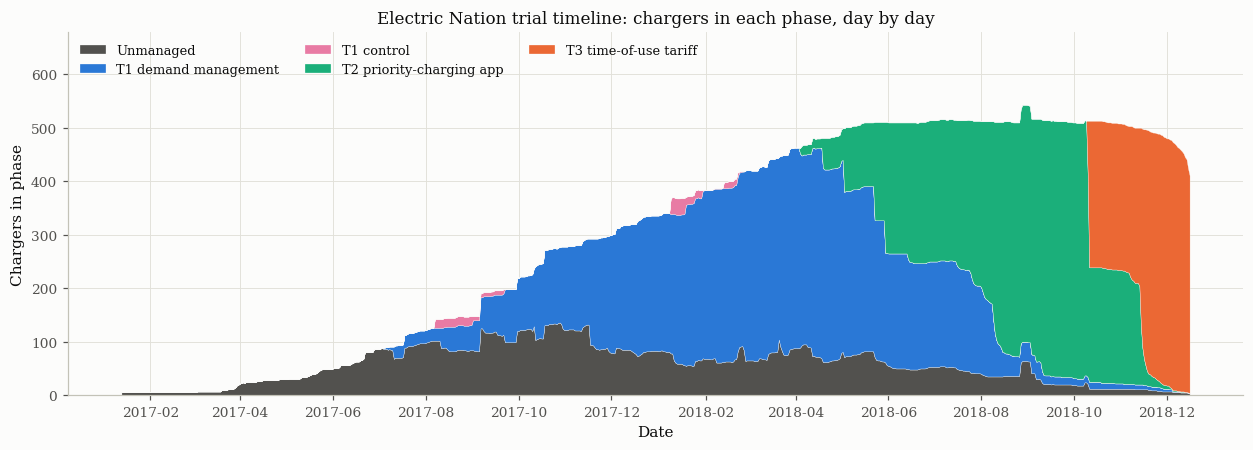

In [11]:
daily = (charger_day[charger_day.phase.isin(PHASE_ALL)]
         .groupby(["date", "phase"]).charger_id.nunique()
         .unstack(fill_value=0).reindex(columns=PHASE_ALL, fill_value=0))
fig, ax = plt.subplots(figsize=(11.5, 4.2))
ax.stackplot(daily.index, [daily[p].values for p in PHASE_ALL],
             colors=[PHASE_COLORS[p] for p in PHASE_ALL], labels=PHASE_ALL, edgecolor=SURFACE, linewidth=0.2)
ax.set_ylim(0, daily.sum(axis=1).max() * 1.25)
ax.set_ylabel("Chargers in phase")
ax.set_xlabel("Date")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.legend(frameon=False, fontsize=8.5, loc="upper left", ncol=3)
ax.set_title("Electric Nation trial timeline: chargers in each phase, day by day")
fig.tight_layout()
savefig(fig, "EN1_trial_timeline")
plt.show()

### Figure EN2 - Vehicle fleet, from the customer survey

(a) Usable battery capacity by drivetrain, with the
median marked on each violin. (b) The most common vehicles, coloured by drivetrain.
More than half the cohort drives a plug-in hybrid or range extender with a small battery, so a
typical session is much smaller than a modern BEV's.

saved -> figures/EN2_vehicle_fleet.png


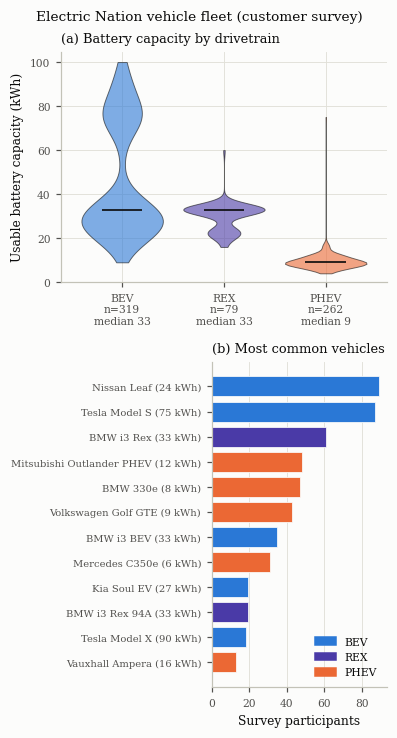

52% of participants drive a PHEV or range extender


In [12]:
fleet = (survey.groupby("vehicle")
         .agg(n=("vehicle", "size"), drivetrain=("drivetrain", lambda s: s.mode().iat[0]),
              battery_kwh=("battery_kwh", "median"))
         .sort_values("n", ascending=False))

batt = {dt: survey.loc[survey.drivetrain == dt, "battery_kwh"].dropna() for dt in DRIVETRAIN_ORDER}

with plt.rc_context(COLUMN_RC):
    # Two subfigures, each laid out on its own, so panel (a) is not narrowed to the left margin
    # that panel (b)'s long vehicle names need.
    fig = plt.figure(figsize=(COL_WIDTH, 6.6), layout="constrained")
    sub_a, sub_b = fig.subfigures(2, 1, height_ratios=[1, 1.3])
    axes = [sub_a.subplots(), sub_b.subplots()]

    ax = axes[0]
    parts = ax.violinplot([batt[d] for d in DRIVETRAIN_ORDER], showmedians=True, showextrema=False, widths=0.8)
    for body, d in zip(parts["bodies"], DRIVETRAIN_ORDER):
        body.set_facecolor(DRIVETRAIN_COLORS[d])
        body.set_edgecolor(INK_PRIMARY)
        body.set_alpha(0.6)
        body.set_linewidth(0.6)
    parts["cmedians"].set_color(INK_PRIMARY)
    parts["cmedians"].set_linewidth(1.1)
    # n and median go in the tick labels.
    ax.set_xticks(range(1, len(DRIVETRAIN_ORDER) + 1))
    ax.set_xticklabels([f"{d}\nn={len(batt[d])}\nmedian {batt[d].median():.0f}" for d in DRIVETRAIN_ORDER])
    ax.set_xlim(0.4, len(DRIVETRAIN_ORDER) + 0.6)
    ax.set_ylim(bottom=0)
    ax.set_ylabel("Usable battery capacity (kWh)")
    ax.set_title("(a) Battery capacity by drivetrain", loc="left")

    ax = axes[1]
    top = fleet.head(12).iloc[::-1]
    ax.barh(range(len(top)), top.n, color=[DRIVETRAIN_COLORS[d] for d in top.drivetrain],
            edgecolor=SURFACE, linewidth=0.5)
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels([f"{i} ({b:.0f} kWh)" for i, b in zip(top.index, top.battery_kwh)], fontsize=6.5)
    ax.set_xlabel("Survey participants")
    ax.grid(axis="y", visible=False)
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=DRIVETRAIN_COLORS[d]) for d in DRIVETRAIN_ORDER],
              labels=DRIVETRAIN_ORDER, frameon=False, loc="lower right")
    ax.set_title("(b) Most common vehicles", loc="left")

    fig.suptitle("Electric Nation vehicle fleet (customer survey)", fontsize=9)
    savefig(fig, "EN2_vehicle_fleet")
    plt.show()
print(f"{(survey.drivetrain != 'BEV').mean():.0%} of participants drive a PHEV or range extender")

### Figure EN3 - Charging frequency per household, by provider

(a) Charging sessions started per week. (b) Share of days in the observation window with any
charging. Both use the observation window as the denominator. The spread is wide: many
households charge daily or more often.

saved -> figures/EN3_charging_frequency.png


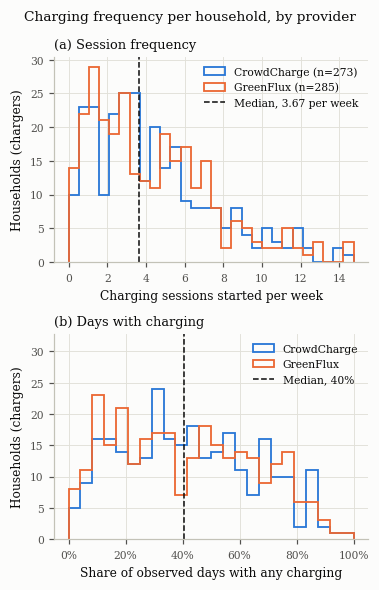

In [13]:
with plt.rc_context(COLUMN_RC):
    fig, axes = plt.subplots(2, 1, figsize=(COL_WIDTH, 5.4))
    ax = axes[0]
    bins = np.linspace(0, cohort.sessions_per_week.quantile(0.995), 29)
    for p in PROVIDERS:
        d = cohort.loc[cohort.provider == p, "sessions_per_week"]
        ax.hist(d.clip(upper=bins[-1]), bins=bins, histtype="step", linewidth=1.2,
                color=PROVIDER_COLORS[p], label=f"{p} (n={len(d)})")
    med = cohort.sessions_per_week.median()
    ax.axvline(med, color=INK_PRIMARY, linestyle="--", linewidth=1.0, label=f"Median, {med:.2f} per week")
    ax.set_xlabel("Charging sessions started per week")
    ax.set_ylabel("Households (chargers)")
    ax.legend(frameon=False, loc="upper right")
    ax.set_title("(a) Session frequency", loc="left")

    ax = axes[1]
    bins2 = np.linspace(0, 1, 25)
    for p in PROVIDERS:
        d = cohort.loc[cohort.provider == p, "frac_days_charging"]
        ax.hist(d, bins=bins2, histtype="step", linewidth=1.2, color=PROVIDER_COLORS[p], label=p)
    med2 = cohort.frac_days_charging.median()
    ax.axvline(med2, color=INK_PRIMARY, linestyle="--", linewidth=1.0, label=f"Median, {med2:.0%}")
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.set_ylim(0, ax.get_ylim()[1] * 1.3)   # headroom so the legend clears the bars
    ax.set_xlabel("Share of observed days with any charging")
    ax.set_ylabel("Households (chargers)")
    ax.legend(frameon=False, loc="upper right")
    ax.set_title("(b) Days with charging", loc="left")

    fig.suptitle("Charging frequency per household, by provider", fontsize=9)
    fig.tight_layout()
    savefig(fig, "EN3_charging_frequency")
    plt.show()

### Figure EN4 - Charging energy by month

For each charger and calendar month (with at least 10 observed days), the mean charging energy per
day, zero days included. The line is the median across charger-months and the band the
interquartile range; the dashed line is the all-year median. EV charging is not weather-driven,
so the seasonal swing is small next to the spread between households. Read with Figure EN1:
late-2018 months are mostly managed charging and 2017 months mostly unmanaged.

saved -> figures/EN4_charging_energy_by_month.png


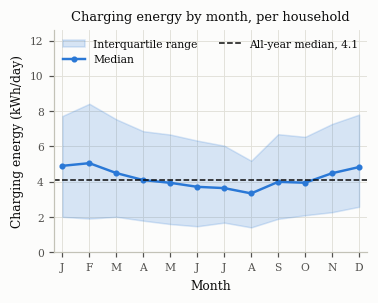

saved -> tables/EN_S_charging_energy_by_month.csv
winter (DJF) median 4.92 vs summer (JJA) 3.56 kWh/day: ratio 1.38


In [14]:
cm = (charger_day[charger_day.charger_id.isin(cohort.charger_id)]
      .groupby(["provider", "charger_id", "month"]).agg(kwh=("kwh", "sum"), days=("kwh", "size")).reset_index())
cm = cm[cm.days >= MIN_MONTH_DAYS]
cm["kwh_per_day"] = cm.kwh / cm.days
monthly = (cm.groupby("month").kwh_per_day
           .agg(q25=lambda s: s.quantile(.25), median="median", q75=lambda s: s.quantile(.75), n="size")
           .reindex(range(1, 13)))
overall = cm.kwh_per_day.median()

with plt.rc_context(COLUMN_RC):
    fig, ax = plt.subplots(figsize=(COL_WIDTH, 2.8))
    x = np.arange(1, 13)
    ax.fill_between(x, monthly.q25, monthly.q75, color=CAT["blue"], alpha=0.18, label="Interquartile range")
    ax.plot(x, monthly["median"], color=CAT["blue"], linewidth=1.6, marker="o", markersize=3, label="Median")
    ax.axhline(overall, color=INK_PRIMARY, linestyle="--", linewidth=1.0, label=f"All-year median, {overall:.1f}")
    ax.set_xticks(x)
    ax.set_xticklabels([m[0] for m in MONTH_LABELS])   # J F M ... so twelve labels fit one column
    ax.set_xlim(0.7, 12.3)
    ax.set_ylim(0, monthly.q75.max() * 1.5)            # headroom so the legend sits above the band
    ax.set_xlabel("Month")
    ax.set_ylabel("Charging energy (kWh/day)")
    ax.legend(frameon=False, loc="upper center", ncol=2)
    ax.set_title("Charging energy by month, per household")
    fig.tight_layout()
    savefig(fig, "EN4_charging_energy_by_month")
    plt.show()

savetable(monthly.round(2).set_axis(MONTH_LABELS), "EN_S_charging_energy_by_month")
winter = monthly.loc[[12, 1, 2], "median"].mean()
summer = monthly.loc[[6, 7, 8], "median"].mean()
print(f"winter (DJF) median {winter:.2f} vs summer (JJA) {summer:.2f} kWh/day: ratio {winter / summer:.2f}")

### Figure EN5 - Start time, weekday vs weekend, by regime (local clock)

The T1 control panel is the behavioural baseline, charging without management: an evening
arrivals peak around 17:30–18:30 on weekdays, a smaller morning peak, and a flatter weekend. It
rests on only 586 sessions, so it is noisier than the other panels. Under T1 demand management and
T2 the back office can defer or throttle a charge, so start times are partly the network's
decision, yet their weekday shape stays close to the control's. Under the T3 time-of-use
tariff, about one weekday session in eight starts in the half-hour after 22:00, when the cheap rate
begins. Weekday and weekend charging differ in every regime, which is why the EV features separate
the two.

saved -> figures/EN5_start_time_weekday_weekend.png


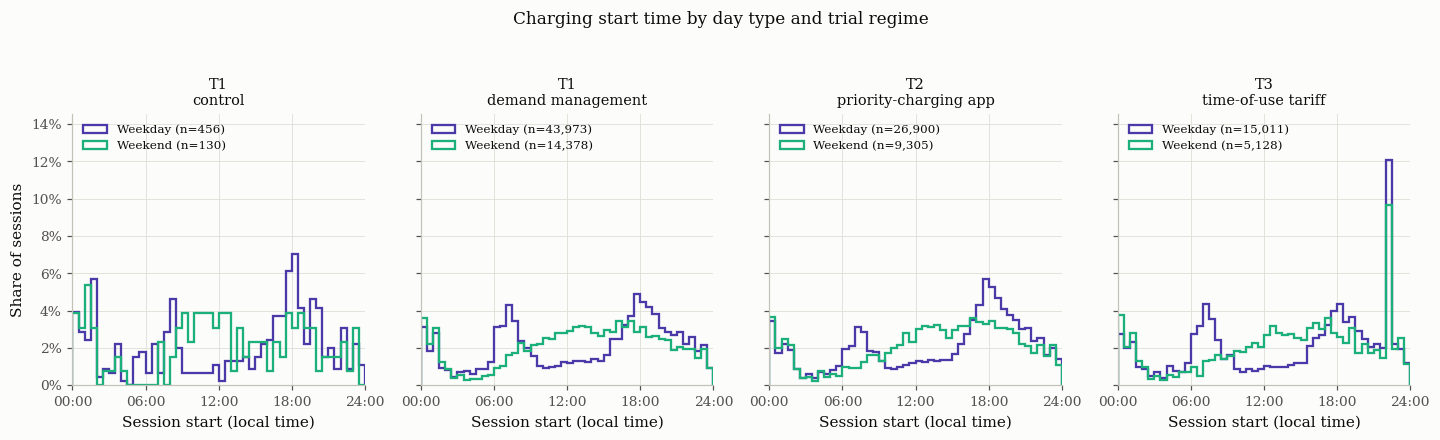

T3 weekday sessions starting 22:00-22:30 local: 12.1%
saved -> tables/EN_S_start_time_by_phase.csv


sessions  median_start  pct_1800_2100  \
phase                    daytype                                          
T1 control               Weekday       456        15.750          0.246   
                         Weekend       130        12.250          0.154   
T1 demand management     Weekday     43973        15.500          0.218   
                         Weekend     14378        13.783          0.157   
T2 priority-charging app Weekday     26900        16.500          0.254   
                         Weekend      9305        14.500          0.183   
T3 time-of-use tariff    Weekday     15011        16.500          0.196   
                         Weekend      5128        15.000          0.143   

                                  pct_overnight  
phase                    daytype                 
T1 control               Weekday          0.298  
                         Weekend          0.254  
T1 demand management     Weekday          0.225  
                         Weekend          0.202  
T2 priority-charging app Weekday          0.223  
                         Weekend          0.214  
T3 time-of-use tariff    Weekday          0.316  
                         Weekend          0.296

In [15]:
fig, axes = plt.subplots(1, len(PHASE_ORDER), figsize=(3.3 * len(PHASE_ORDER), 3.8), sharex=True, sharey=True)
bins = np.arange(0, 24.5, 0.5)
for ax, phase in zip(axes, PHASE_ORDER):
    d = sessions[sessions.phase == phase]
    for daytype, color in [("Weekday", WEEKDAY_COLOR), ("Weekend", WEEKEND_COLOR)]:
        dd = d[d.daytype == daytype]
        ax.hist(dd.start_hour, bins=bins, weights=np.full(len(dd), 1 / len(dd)), histtype="step",
                linewidth=1.5, color=color, label=f"{daytype} (n={len(dd):,})")
    ax.set_xlim(0, 24)
    ax.set_xticks(range(0, 25, 6))
    ax.set_xticklabels([f"{h:02d}:00" for h in range(0, 25, 6)])
    ax.set_xlabel("Session start (local time)")
    ax.set_title(phase.replace(" ", "\n", 1), fontsize=9.5)
    ax.legend(frameon=False, fontsize=7.8, loc="upper left")
axes[0].set_ylabel("Share of sessions")
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
axes[0].set_ylim(0, axes[0].get_ylim()[1] * 1.15)
fig.suptitle("Charging start time by day type and trial regime", y=1.04, fontsize=11)
fig.tight_layout()
savefig(fig, "EN5_start_time_weekday_weekend")
plt.show()

t3 = sessions[(sessions.phase == "T3 time-of-use tariff") & (sessions.daytype == "Weekday")]
print(f"T3 weekday sessions starting 22:00-22:30 local: {t3.start_hour.between(22, 22.5, inclusive='left').mean():.1%}")

start_summary = (sessions[sessions.phase.isin(PHASE_ORDER)]
                 .groupby(["phase", "daytype"])
                 .agg(sessions=("start_hour", "size"),
                      median_start=("start_hour", "median"),
                      pct_1800_2100=("start_hour", lambda s: s.between(18, 21).mean()),
                      pct_overnight=("start_hour", lambda s: ((s >= 22) | (s < 6)).mean()))
                 .reindex(PHASE_ORDER, level="phase")
                 .round(3))
savetable(start_summary, "EN_S_start_time_by_phase")
start_summary

### Figure EN6 - Mean demand per charger, by regime (local clock)

The mean kWh per half-hour drawn by one charger, averaged over every charger-day in that regime,
including days with no charging. This is the average load an EV adds to a household meter under
each regime. Shown on the local clock, so the four clock-change dates are excluded here only.

saved -> figures/EN6_mean_demand_by_regime.png


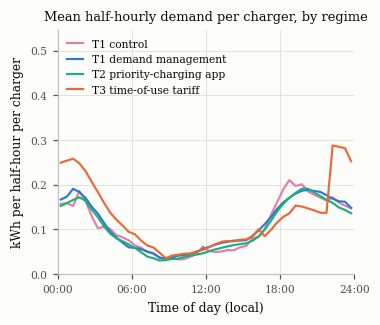

saved -> tables/EN_S_mean_demand_by_regime.csv


,Charger-days,Mean kWh per charger-day
T1 control,1205,5.12
T1 demand management,85177,5.29
T2 priority-charging app,60062,4.94
T3 time-of-use tariff,24059,6.14


In [16]:
slot_sum = con.execute(f"""
    WITH s AS (SELECT time_bucket(INTERVAL 30 MINUTE, t_local) AS ts, kwh, {PHASE_SQL} FROM samples)
    SELECT phase, hour(ts) * 2 + minute(ts) // 30 AS slot, sum(kwh) AS kwh
    FROM s WHERE CAST(ts AS DATE) NOT IN ({bst_list})
    GROUP BY 1, 2
""").fetchdf()
n_days = (charger_day[~charger_day.date.isin(pd.to_datetime(BST_DATES))]
          .groupby("phase").size())

profiles = {}
for ph in PHASE_ORDER:
    s = slot_sum[slot_sum.phase == ph].set_index("slot").kwh.reindex(range(48), fill_value=0)
    profiles[ph] = s / n_days[ph]

with plt.rc_context(COLUMN_RC):
    fig, ax = plt.subplots(figsize=(COL_WIDTH, 3.0))
    for ph in PHASE_ORDER:
        ax.plot(np.arange(48) + 0.5, profiles[ph].values, color=PHASE_COLORS[ph], linewidth=1.4, label=ph)
    hhmm_axis(ax, step_hours=6)
    ax.set_xlim(0, 48)
    ax.set_ylim(0, max(p.max() for p in profiles.values()) * 1.9)   # headroom for the four-row legend
    ax.set_xlabel("Time of day (local)")
    ax.set_ylabel("kWh per half-hour per charger")
    ax.legend(frameon=False, loc="upper left", handlelength=1.5)
    ax.set_title("Mean half-hourly demand per charger, by regime")
    fig.tight_layout()
    savefig(fig, "EN6_mean_demand_by_regime")
    plt.show()

# The charger-day counts and daily totals behind each line.
demand_summary = pd.DataFrame({
    "Charger-days": [int(n_days[ph]) for ph in PHASE_ORDER],
    "Mean kWh per charger-day": [round(profiles[ph].sum(), 2) for ph in PHASE_ORDER],
}, index=PHASE_ORDER)
savetable(demand_summary, "EN_S_mean_demand_by_regime")
demand_summary

### Figure EN7 - Carpet plots for three chargers (GMT)

Date across, time of day (GMT) up, colour is kWh per half-hour, so each charging session is a
short vertical stripe. The three chargers are chosen programmatically from those with a window of
at least 330 days: the heaviest user, the charger closest to the median weekly cadence, and an
infrequent charger from the lowest quartile of frequency that still charges at least fortnightly.

saved -> figures/EN7_carpet_plots.png


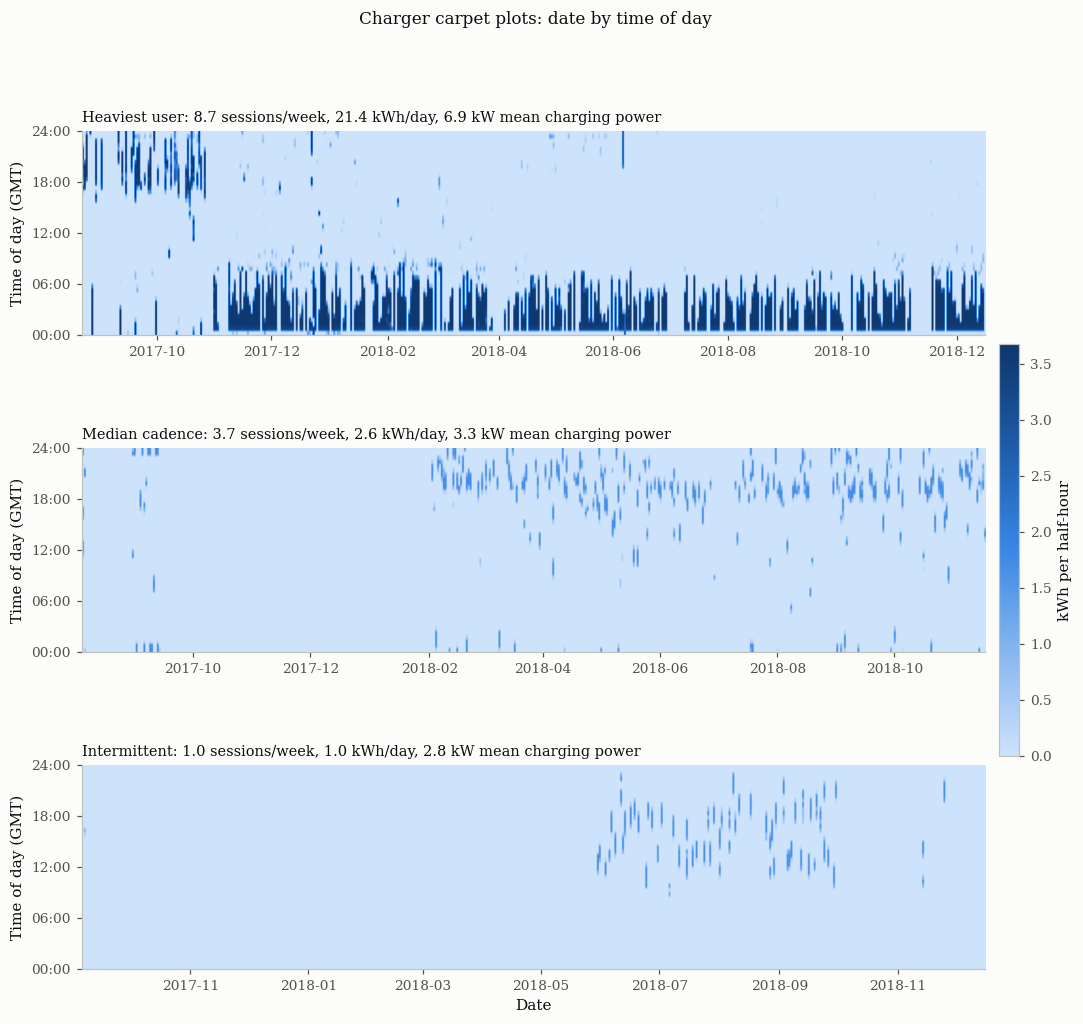

In [17]:
pool = cohort[cohort.window_days >= 330].copy()
low = pool[(pool.sessions_per_week <= pool.sessions_per_week.quantile(0.25)) & (pool.n_sessions >= 26)]
pick = {
    "Heaviest user": pool.loc[pool.kwh_per_day.idxmax()],
    "Median cadence": pool.loc[(pool.sessions_per_week - pool.sessions_per_week.median()).abs().idxmin()],
    "Intermittent": low.iloc[(low.sessions_per_week - pool.sessions_per_week.quantile(0.10)).abs().argsort().iloc[0]],
}

fig, axes = plt.subplots(len(pick), 1, figsize=(11, 3.3 * len(pick)))
fig.subplots_adjust(hspace=0.55)   # room for each panel title below the date labels above it
VMAX = 32 * VOLTS / 2000   # the physical half-hourly maximum of a 32 A charger
for ax, (label, row) in zip(axes, pick.items()):
    d = con.execute(f"""
        SELECT ts, kwh FROM hh_gmt WHERE provider = '{row.provider}' AND charger_id = '{row.charger_id}'
    """).fetchdf()
    d["date"] = d.ts.dt.normalize()
    d["slot"] = d.ts.dt.hour * 2 + d.ts.dt.minute // 30
    mat = (d.pivot_table(index="slot", columns="date", values="kwh", aggfunc="sum")
           .reindex(index=range(48))
           .reindex(columns=pd.date_range(row.first_date, row.last_date, freq="D")).fillna(0.0))
    im = ax.imshow(mat.values, aspect="auto", origin="lower", cmap=SEQ_BLUE_CMAP, vmin=0, vmax=VMAX,
                   extent=[mdates.date2num(mat.columns.min()), mdates.date2num(mat.columns.max()), 0, 48])
    hhmm_axis(ax, "y", step_hours=6)
    ax.set_ylabel("Time of day (GMT)")
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.grid(False)
    ax.set_title(f"{label}: {row.sessions_per_week:.1f} sessions/week, {row.kwh_per_day:.1f} kWh/day, "
                 f"{row.mean_charge_kw:.1f} kW mean charging power", fontsize=9.5, loc="left")
axes[-1].set_xlabel("Date")
cbar = fig.colorbar(im, ax=axes, fraction=0.022, pad=0.015)
cbar.set_label("kWh per half-hour")
fig.suptitle("Charger carpet plots: date by time of day", y=0.99, fontsize=11)
savefig(fig, "EN7_carpet_plots")
plt.show()

## 5. Notes and limitations

- Energy is calculated from current, assuming 230 V and unity power factor, so absolute kWh may be
  off by about ±4%.
- The two providers record differently. CrowdCharge logs nothing when no car is plugged in, so
  frequencies use the observation window, and GreenFlux's 15-minute blocks make sessions look
  longer and lower in power.
- The survey can't be linked to individual chargers, so Figure EN2 describes the cohort as a
  whole.
- The 2017–18 fleet had small batteries and many plug-in hybrids, so session energies are lower
  than they would be today.
- Season and regime overlap, because T3 ran only from October to December 2018.
- T1 control is small (59 chargers) and stands in for unmanaged charging, so its results are
  noisier than the other regimes'.